# Лабораторная работа №1 — разведочный анализ данных

**Тема:** исследование характеристик компьютерных игр платформы Steam.

В работе выполняется разведочный анализ подготовленной Iceberg-таблицы средствами Apache Spark. Анализ включает проверку качества данных, обработку пропусков и дубликатов, описательную статистику, исследование распределений и выбросов, анализ многозначных категориальных признаков и корреляционный анализ.

> Исходная Iceberg-таблица не изменяется. Все операции очистки и формирования признаков выполняются в рабочем DataFrame этой лабораторной работы.

## 1. Инициализация

Подключаем необходимые библиотеки, создаём Spark-сессию и задаём пути для результатов анализа и графиков.

In [1]:
%matplotlib inline

import sys
from pathlib import Path
from itertools import combinations

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pyspark.sql.functions import (
    array_distinct,
    col,
    desc,
    explode,
    floor,
    isnan,
    log1p,
    max as spark_max,
    min as spark_min,
    percentile_approx,
    size,
    sum as spark_sum,
    when,
    year,
)

from pyspark.sql.types import (
    ArrayType,
    NumericType,
    StringType,
)

# Корень проекта в sys.path (src/ лежит на уровень выше notebooks/)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.spark_session import create_spark, catalog_name

spark = create_spark("Lab_1_data_analysis")

# Имя таблицы по требованию преподавателя: каталог.фамилия_database.таблица
CATALOG = catalog_name()  # spark_catalog на кластере, local в docker
DATABASE_NAME = "sidsky_nikita_database"
TABLE_NAME = f"{CATALOG}.{DATABASE_NAME}.steam_games"

RESULTS_DIR = PROJECT_ROOT / "output" / "results"
PLOTS_DIR = PROJECT_ROOT / "output" / "plots"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Каталог Iceberg:", CATALOG)
print("Таблица:", TABLE_NAME)
print("Результаты:", RESULTS_DIR)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/18 20:22:54 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


Каталог Iceberg: spark_catalog
Таблица: spark_catalog.sidsky_nikita_database.steam_games
Результаты: /home/user7/sidsky_nikita_sapr11/big_data_light/output/results


## 2. Загрузка данных

Для анализа используется подготовленная Iceberg-таблица, полученная в первой части лабораторной работы.

In [2]:
df = spark.table(TABLE_NAME)

total_rows = df.count()

print("Количество строк:", f"{total_rows:,}")
print("Количество столбцов:", len(df.columns))

df.printSchema()

Количество строк: 141,148
Количество столбцов: 24
root
 |-- app_id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- price: double (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- positive: long (nullable = true)
 |-- negative: long (nullable = true)
 |-- recommendations: long (nullable = true)
 |-- peak_ccu: long (nullable = true)
 |-- metacritic_score: integer (nullable = true)
 |-- average_playtime_forever: long (nullable = true)
 |-- median_playtime_forever: long (nullable = true)
 |-- achievements: integer (nullable = true)
 |-- dlc_count: integer (nullable = true)
 |-- windows: boolean (nullable = true)
 |-- mac: boolean (nullable = true)
 |-- linux: boolean (nullable = true)
 |-- estimated_owners

In [3]:
df.orderBy("app_id").show(20, truncate=False)

+------+------------------------------+------------+-----+--------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------+--------+---------------+--------+----------------+------------------------+-----------------------+------------+-

## 3. Проверка целостности набора данных

Сначала проверяем основной идентификатор игры. Для корректно загруженного набора каждая игра должна иметь уникальный `app_id`.

In [4]:
null_app_id = df.filter(col("app_id").isNull()).count()

unique_app_id = (
    df
    .select("app_id")
    .distinct()
    .count()
)

duplicate_app_ids = (
    df
    .filter(col("app_id").isNotNull())
    .groupBy("app_id")
    .count()
    .filter(col("count") > 1)
    .orderBy(desc("count"))
)

print("NULL app_id:", f"{null_app_id:,}")
print("Уникальных app_id:", f"{unique_app_id:,}")
print("app_id с повторениями:", f"{duplicate_app_ids.count():,}")

duplicate_app_ids.show(20, truncate=False)

NULL app_id: 0
Уникальных app_id: 141,148


app_id с повторениями: 0


+------+-----+
|app_id|count|
+------+-----+
+------+-----+



## 4. Анализ пропущенных значений

Для каждого признака определяем количество и долю пропущенных значений. Для числовых признаков дополнительно учитывается `NaN`.

In [5]:
float_columns = {
    name
    for name, dtype in df.dtypes
    if dtype in {"float", "double"}
}

missing_expressions = []

for column_name in df.columns:
    missing_condition = col(column_name).isNull()

    if column_name in float_columns:
        missing_condition = missing_condition | isnan(col(column_name))

    missing_expressions.append(
        spark_sum(
            when(missing_condition, 1).otherwise(0)
        ).alias(column_name)
    )

missing_counts = (
    df
    .select(*missing_expressions)
    .first()
    .asDict()
)

missing_report = pd.DataFrame(
    {
        "column": df.columns,
        "missing_count": [
            missing_counts[column_name]
            for column_name in df.columns
        ],
    }
)

missing_report["missing_percent"] = (
    missing_report["missing_count"]
    / total_rows
    * 100
)

missing_report = (
    missing_report
    .sort_values("missing_percent", ascending=False)
    .reset_index(drop=True)
)

display(missing_report)

,column,missing_count,missing_percent
0,metacritic_score,42213,29.906906
1,recommendations,34891,24.719443
2,achievements,18388,13.027461
3,supported_languages_count,8396,5.948366
4,price,1236,0.875677
5,release_date,82,0.058095
6,full_audio_languages_count,20,0.014170
7,name,15,0.010627
8,mac,14,0.009919
9,windows,14,0.009919


In [6]:
missing_report.to_csv(
    RESULTS_DIR / "missing_values.csv",
    index=False,
)

### Визуализация пропущенных значений

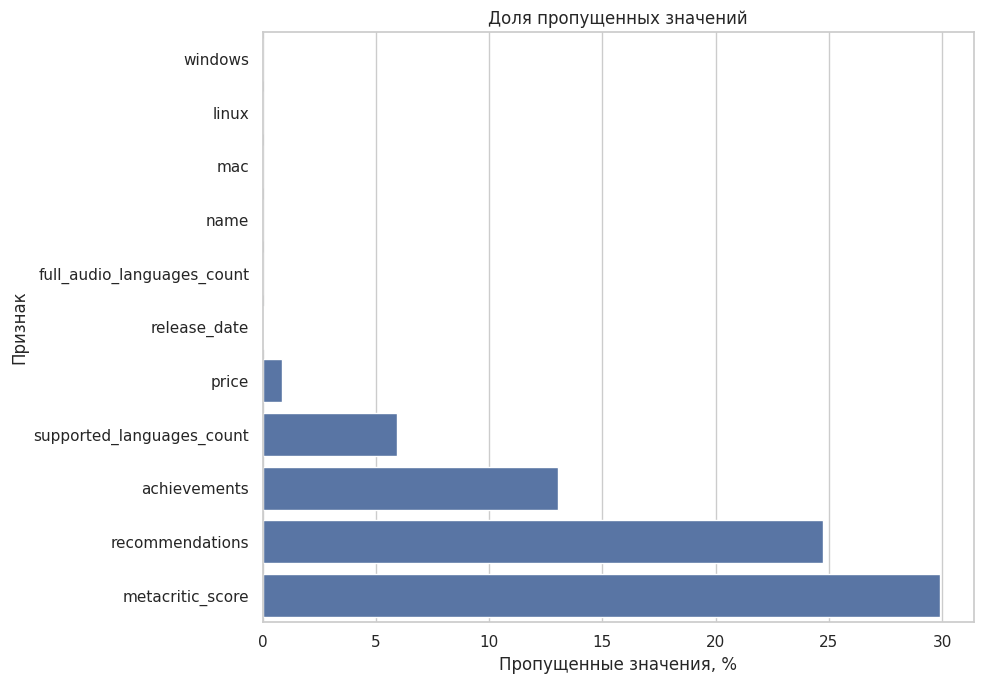

In [7]:
missing_plot = (
    missing_report[
        missing_report["missing_count"] > 0
    ]
    .sort_values("missing_percent")
)

if not missing_plot.empty:
    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=missing_plot,
        x="missing_percent",
        y="column",
    )
    plt.xlabel("Пропущенные значения, %")
    plt.ylabel("Признак")
    plt.title("Доля пропущенных значений")
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / "01_missing_values.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

## 5. Проверка пустых строк и многозначных признаков

`genres`, `categories` и `tags` представлены массивами. Для них отдельно учитываются `NULL` и пустые массивы. Это позволяет не путать отсутствие значения с корректным пустым списком.

In [8]:
string_columns = [
    field.name
    for field in df.schema.fields
    if isinstance(field.dataType, StringType)
]

empty_string_report = []

for column_name in string_columns:
    empty_count = (
        df
        .filter(
            col(column_name).isNotNull()
            & (col(column_name) == "")
        )
        .count()
    )

    empty_string_report.append(
        {
            "column": column_name,
            "empty_count": empty_count,
            "empty_percent": empty_count / total_rows * 100,
        }
    )

empty_string_report = pd.DataFrame(empty_string_report)

display(empty_string_report)

,column,empty_count,empty_percent
0,name,0,0.0


In [9]:
array_columns = [
    field.name
    for field in df.schema.fields
    if isinstance(field.dataType, ArrayType)
]

array_report = []

for column_name in array_columns:
    stats = (
        df
        .select(
            spark_sum(
                when(col(column_name).isNull(), 1).otherwise(0)
            ).alias("null_count"),
            spark_sum(
                when(
                    col(column_name).isNotNull()
                    & (size(col(column_name)) == 0),
                    1,
                ).otherwise(0)
            ).alias("empty_count"),
            spark_max(size(col(column_name))).alias("max_size"),
        )
        .first()
    )

    array_report.append(
        {
            "column": column_name,
            "null_count": stats["null_count"],
            "empty_count": stats["empty_count"],
            "max_size": stats["max_size"],
        }
    )

array_report = pd.DataFrame(array_report)

array_report["null_percent"] = (
    array_report["null_count"] / total_rows * 100
)

array_report["empty_percent"] = (
    array_report["empty_count"] / total_rows * 100
)

display(array_report)

,column,null_count,empty_count,max_size,null_percent,empty_percent
0,genres,0,8431,19,0.0,5.973163
1,categories,0,8962,34,0.0,6.349364
2,tags,0,57688,21,0.0,40.870576


## 6. Проверка нулевых значений

Нулевое значение не всегда является пропуском. Например, `price = 0` означает бесплатную игру, а `dlc_count = 0` — отсутствие DLC. Поэтому сначала определяем частоту нулей, а решение о преобразовании принимаем для каждого признака отдельно.

In [10]:
numeric_columns = [
    field.name
    for field in df.schema.fields
    if isinstance(field.dataType, NumericType)
]

zero_expressions = [
    spark_sum(
        when(col(column_name) == 0, 1).otherwise(0)
    ).alias(column_name)
    for column_name in numeric_columns
]

zero_counts = (
    df
    .select(*zero_expressions)
    .first()
    .asDict()
)

zero_report = pd.DataFrame(
    {
        "column": numeric_columns,
        "zero_count": [
            zero_counts[column_name]
            for column_name in numeric_columns
        ],
    }
)

zero_report["zero_percent"] = (
    zero_report["zero_count"] / total_rows * 100
)

zero_report = (
    zero_report
    .sort_values("zero_percent", ascending=False)
    .reset_index(drop=True)
)

display(zero_report)

,column,zero_count,zero_percent
0,average_playtime_forever,129775,91.942500
1,median_playtime_forever,129775,91.942500
2,peak_ccu,121432,86.031683
3,dlc_count,120780,85.569757
4,estimated_owners_min,115523,81.845297
5,metacritic_score,94645,67.053731
6,full_audio_languages_count,88579,62.756114
7,recommendations,84040,59.540341
8,negative,73618,52.156602
9,positive,60692,42.998838


In [11]:
zero_report.to_csv(
    RESULTS_DIR / "zero_values.csv",
    index=False,
)

## 7. Проверка корректности значений

Проверяем значения, которые физически или логически не должны встречаться в наборе. На этом этапе строки не удаляются.

In [12]:
validation_rules = [
    ("invalid_app_id", "app_id <= 0", col("app_id") <= 0),
    ("negative_price", "price < 0", col("price") < 0),
    ("negative_owners_min", "estimated_owners_min < 0", col("estimated_owners_min") < 0),
    ("negative_owners_max", "estimated_owners_max < 0", col("estimated_owners_max") < 0),
    (
        "owners_min_gt_max",
        "estimated_owners_min > estimated_owners_max",
        col("estimated_owners_min") > col("estimated_owners_max"),
    ),
    ("negative_positive", "positive < 0", col("positive") < 0),
    ("negative_negative", "negative < 0", col("negative") < 0),
    ("negative_recommendations", "recommendations < 0", col("recommendations") < 0),
    ("negative_peak_ccu", "peak_ccu < 0", col("peak_ccu") < 0),
    (
        "invalid_metacritic",
        "metacritic_score < 0 or > 100",
        (col("metacritic_score") < 0) | (col("metacritic_score") > 100),
    ),
    (
        "negative_avg_playtime",
        "average_playtime_forever < 0",
        col("average_playtime_forever") < 0,
    ),
    (
        "negative_median_playtime",
        "median_playtime_forever < 0",
        col("median_playtime_forever") < 0,
    ),
    ("negative_achievements", "achievements < 0", col("achievements") < 0),
    ("negative_dlc_count", "dlc_count < 0", col("dlc_count") < 0),
    (
        "negative_supported_languages",
        "supported_languages_count < 0",
        col("supported_languages_count") < 0,
    ),
    (
        "negative_audio_languages",
        "full_audio_languages_count < 0",
        col("full_audio_languages_count") < 0,
    ),
    (
        "audio_gt_supported",
        "full_audio_languages_count > supported_languages_count",
        col("full_audio_languages_count") > col("supported_languages_count"),
    ),
]

validation_counts = (
    df
    .select(
        *[
            spark_sum(
                when(condition, 1).otherwise(0)
            ).alias(rule_name)
            for rule_name, _, condition in validation_rules
        ]
    )
    .first()
    .asDict()
)

validation_report = pd.DataFrame(
    [
        {
            "rule": rule_name,
            "condition": description,
            "count": validation_counts[rule_name],
        }
        for rule_name, description, _ in validation_rules
    ]
)

display(validation_report)

,rule,condition,count
0,invalid_app_id,app_id <= 0,0
1,negative_price,price < 0,0
2,negative_owners_min,estimated_owners_min < 0,0
3,negative_owners_max,estimated_owners_max < 0,0
4,owners_min_gt_max,estimated_owners_min > estimated_owners_max,0
5,negative_positive,positive < 0,0
6,negative_negative,negative < 0,0
7,negative_recommendations,recommendations < 0,0
8,negative_peak_ccu,peak_ccu < 0,0
9,invalid_metacritic,metacritic_score < 0 or > 100,0


## 8. Удаление дубликатов внутри массивов

Одинаковые категории у разных игр являются нормальными данными. Однако если одна и та же категория встречается несколько раз **внутри списка одной игры**, это дублирование одного значения и его можно устранить.

Для этого создаём рабочий DataFrame `df_clean`. Исходный `df` при этом сохраняется без изменений.

In [13]:
df_clean = (
    df
    .withColumn(
        "genres",
        array_distinct(col("genres")),
    )
    .withColumn(
        "categories",
        array_distinct(col("categories")),
    )
    .withColumn(
        "tags",
        array_distinct(col("tags")),
    )
)

In [14]:
array_duplicate_before = []

for column_name in ["genres", "categories", "tags"]:
    duplicate_count = (
        df
        .filter(
            size(array_distinct(col(column_name)))
            < size(col(column_name))
        )
        .count()
    )

    array_duplicate_before.append(
        {
            "column": column_name,
            "rows_with_duplicates": duplicate_count,
            "percent": duplicate_count / total_rows * 100,
        }
    )

array_duplicate_before = pd.DataFrame(array_duplicate_before)

display(array_duplicate_before)

,column,rows_with_duplicates,percent
0,genres,0,0.000000
1,categories,1659,1.175362
2,tags,0,0.000000


In [15]:
array_duplicate_after = []

for column_name in ["genres", "categories", "tags"]:
    duplicate_count = (
        df_clean
        .filter(
            size(array_distinct(col(column_name)))
            < size(col(column_name))
        )
        .count()
    )

    array_duplicate_after.append(
        {
            "column": column_name,
            "rows_with_duplicates": duplicate_count,
        }
    )

array_duplicate_after = pd.DataFrame(array_duplicate_after)

display(array_duplicate_after)

,column,rows_with_duplicates
0,genres,0
1,categories,0
2,tags,0


## 9. Обработка пропусков и формирование аналитических признаков

На основании предварительного анализа применяем только те преобразования, для которых есть содержательное основание:

- нулевая оценка `Metacritic` рассматривается как отсутствие оценки и заменяется на `NULL`;
- пропуски в количественных признаках не заполняются искусственными значениями, чтобы не создавать несуществующие наблюдения;
- пустые массивы `genres`, `categories` и `tags` сохраняются;
- `0` в `price`, `dlc_count`, времени игры и других количественных признаках сохраняется как возможное реальное значение;
- для анализа популярности создаются суммарное количество отзывов и доля положительных отзывов.

Дополнительно создаются признаки года выпуска, количества жанров/категорий/тегов и поддерживаемых платформ.

In [16]:
df_clean = (
    df_clean
    .withColumn(
        "metacritic_score",
        when(
            col("metacritic_score") == 0,
            None,
        ).otherwise(
            col("metacritic_score")
        ),
    )
    .withColumn(
        "reviews_total",
        col("positive") + col("negative"),
    )
    .withColumn(
        "positive_ratio",
        when(
            col("positive") + col("negative") > 0,
            col("positive")
            / (col("positive") + col("negative")),
        ),
    )
    .withColumn(
        "release_year",
        year(col("release_date")),
    )
    .withColumn(
        "is_free",
        when(
            col("price").isNull(),
            None,
        ).otherwise(
            col("price") == 0
        ),
    )
    .withColumn(
        "genres_count",
        size(col("genres")),
    )
    .withColumn(
        "categories_count",
        size(col("categories")),
    )
    .withColumn(
        "tags_count",
        size(col("tags")),
    )
    .withColumn(
        "platform_count",
        when(
            col("windows").isNull()
            | col("mac").isNull()
            | col("linux").isNull(),
            None,
        ).otherwise(
            col("windows").cast("integer")
            + col("mac").cast("integer")
            + col("linux").cast("integer")
        ),
    )
)

In [17]:
print("Строк до обработки:", f"{df.count():,}")
print("Строк после обработки:", f"{df_clean.count():,}")

df_clean.select(
    "app_id",
    "name",
    "release_year",
    "price",
    "is_free",
    "reviews_total",
    "positive_ratio",
    "metacritic_score",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
).show(20, truncate=False)

Строк до обработки: 141,148
Строк после обработки: 141,148
+------+-----------------------------------------+------------+-----+-------+-------------+------------------+----------------+------------+----------------+----------+--------------+
|app_id|name                                     |release_year|price|is_free|reviews_total|positive_ratio    |metacritic_score|genres_count|categories_count|tags_count|platform_count|
+------+-----------------------------------------+------------+-----+-------+-------------+------------------+----------------+------------+----------------+----------+--------------+
|939790|Royal Alchemist                          |2020        |19.99|false  |305          |0.9442622950819672|NULL            |3           |2               |20        |3             |
|939850|The Dark Pictures Anthology: Man of Medan|2019        |19.99|false  |11609        |0.7590662417090188|75              |1           |13              |20        |1             |
|939870|BlackberryNOV

## 10. Проверка результата обработки

Убеждаемся, что количество игр не изменилось, идентификаторы остались уникальными, а нулевые значения `Metacritic` больше не рассматриваются как оценки.

In [18]:
clean_rows = df_clean.count()
clean_unique_app_id = df_clean.select("app_id").distinct().count()

print("Количество строк:", f"{clean_rows:,}")
print("Уникальных app_id:", f"{clean_unique_app_id:,}")
print("Изменение количества строк:", clean_rows - total_rows)

print(
    "Metacritic = 0:",
    df_clean.filter(col("metacritic_score") == 0).count(),
)

print(
    "Metacritic не NULL:",
    df_clean.filter(col("metacritic_score").isNotNull()).count(),
)

Количество строк: 141,148
Уникальных app_id: 141,148
Изменение количества строк: 0
Metacritic = 0: 0
Metacritic не NULL: 4290


## 11. Описательная статистика числовых признаков

Для признаков с выраженной асимметрией медиана и квартили информативнее среднего значения, поэтому в статистике рассматриваются оба типа характеристик.

In [19]:
analysis_numeric_columns = [
    "price",
    "estimated_owners_min",
    "estimated_owners_max",
    "estimated_owners_avg",
    "positive",
    "negative",
    "reviews_total",
    "positive_ratio",
    "recommendations",
    "peak_ccu",
    "metacritic_score",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
]

df_clean.select(
    *analysis_numeric_columns
).summary(
    "count",
    "min",
    "25%",
    "50%",
    "mean",
    "75%",
    "max",
).show(truncate=False)

26/09/18 20:40:49 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+--------------------+--------------------+--------------------+-----------------+------------------+------------------+------------------+---------------+-----------------+----------------+------------------------+-----------------------+------------------+------------------+-------------------------+--------------------------+-----------------+-----------------+-----------------+-----------------+
|summary|price            |estimated_owners_min|estimated_owners_max|estimated_owners_avg|positive         |negative          |reviews_total     |positive_ratio    |recommendations|peak_ccu         |metacritic_score|average_playtime_forever|median_playtime_forever|achievements      |dlc_count         |supported_languages_count|full_audio_languages_count|genres_count     |categories_count |tags_count       |platform_count   |
+-------+-----------------+--------------------+--------------------+--------------------+-----------------+------------------+---------------

## 12. Анализ распределений числовых признаков

Показатели популярности и активности пользователей имеют длинный правый хвост. Поэтому для наиболее скошенных величин дополнительно используется логарифмическое преобразование `log(1 + x)`. Оно применяется только для визуализации и не удаляет реальные экстремальные значения.

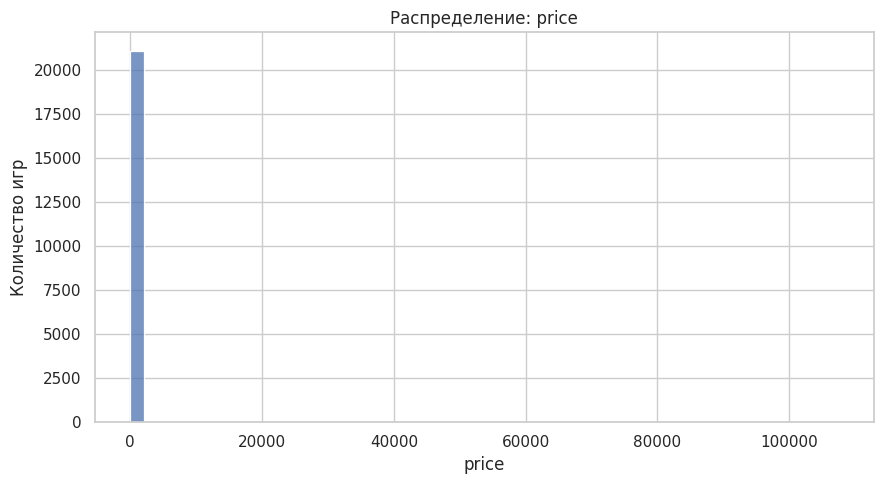

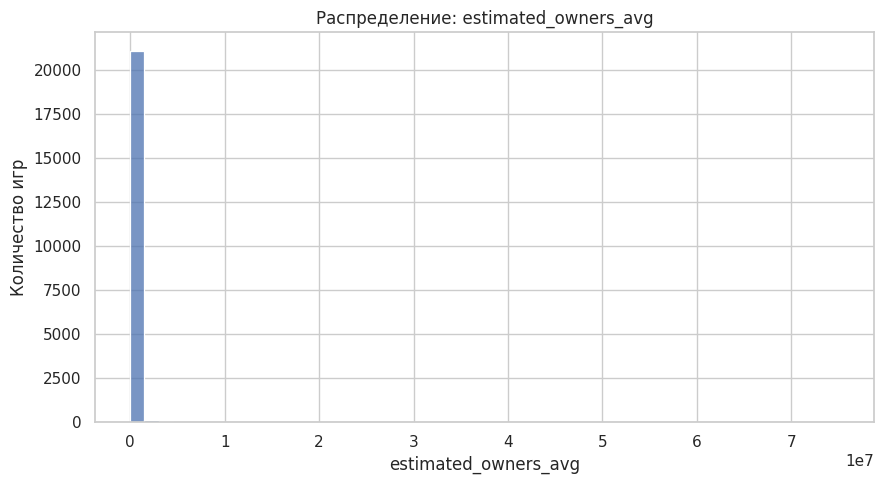

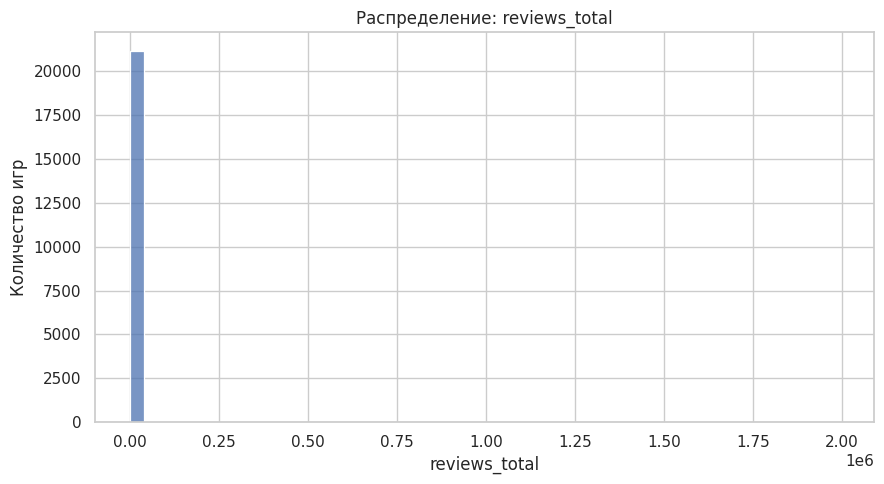

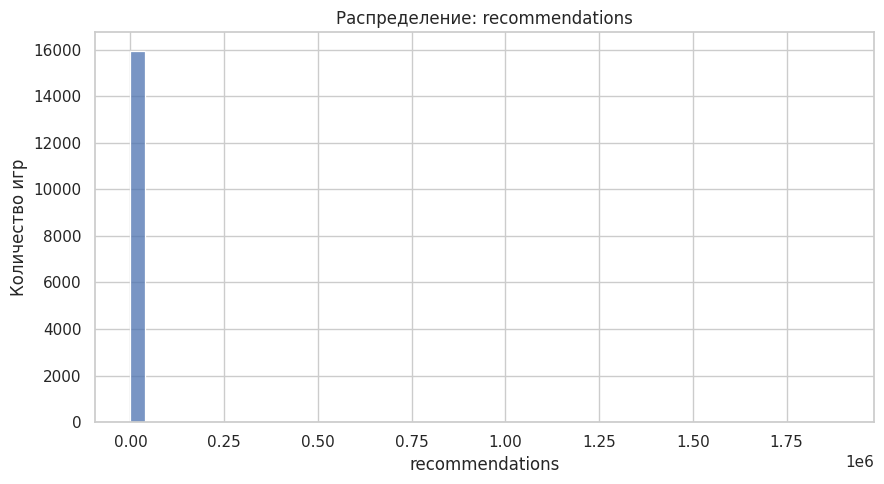

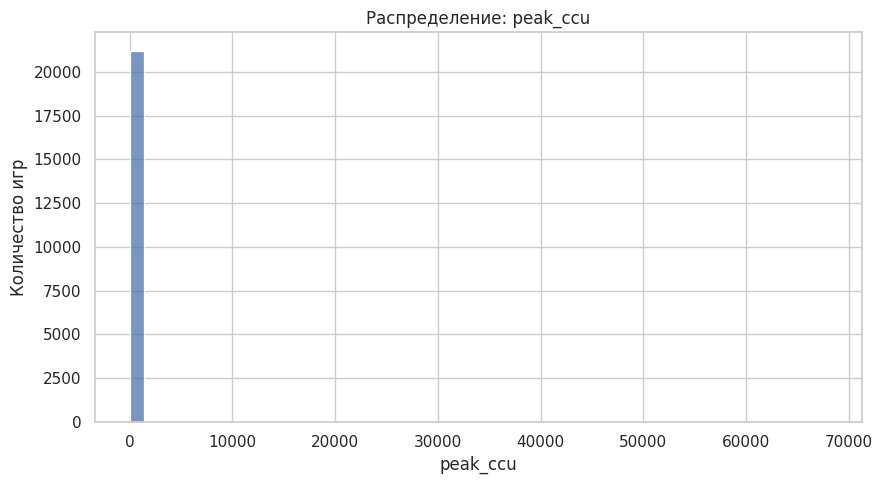

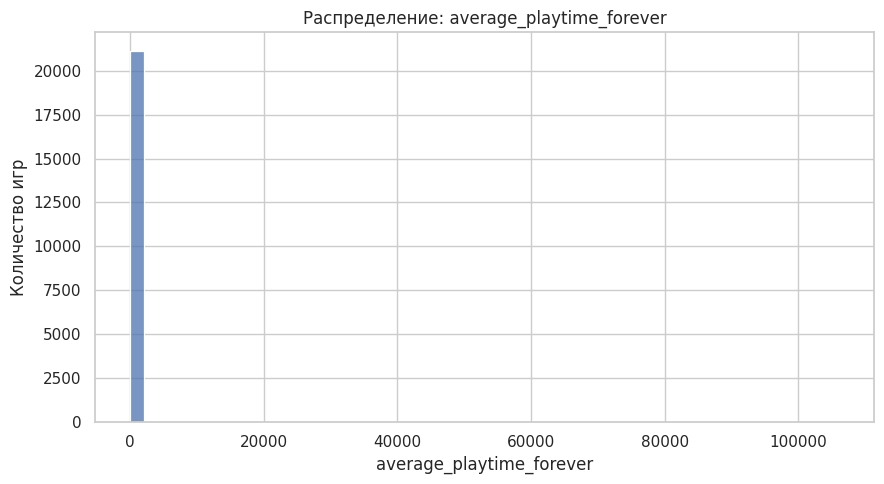

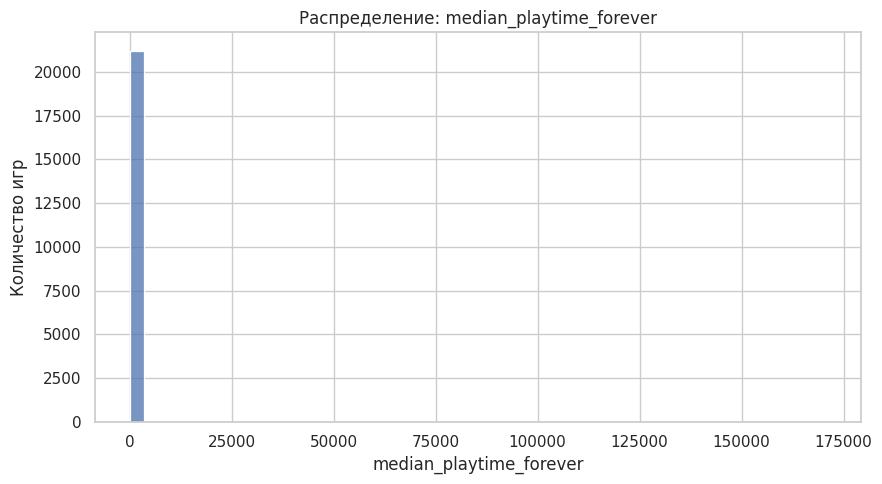

In [20]:
distribution_columns = [
    "price",
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
    "average_playtime_forever",
    "median_playtime_forever",
]

plot_pdf = (
    df_clean
    .select(*distribution_columns)
    .sample(False, 0.15, seed=42)
    .toPandas()
)

for column_name in distribution_columns:
    series = plot_pdf[column_name].dropna()

    if series.empty:
        continue

    plt.figure(figsize=(9, 5))
    sns.histplot(series, bins=50)
    plt.xlabel(column_name)
    plt.ylabel("Количество игр")
    plt.title(f"Распределение: {column_name}")
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / f"02_distribution_{column_name}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

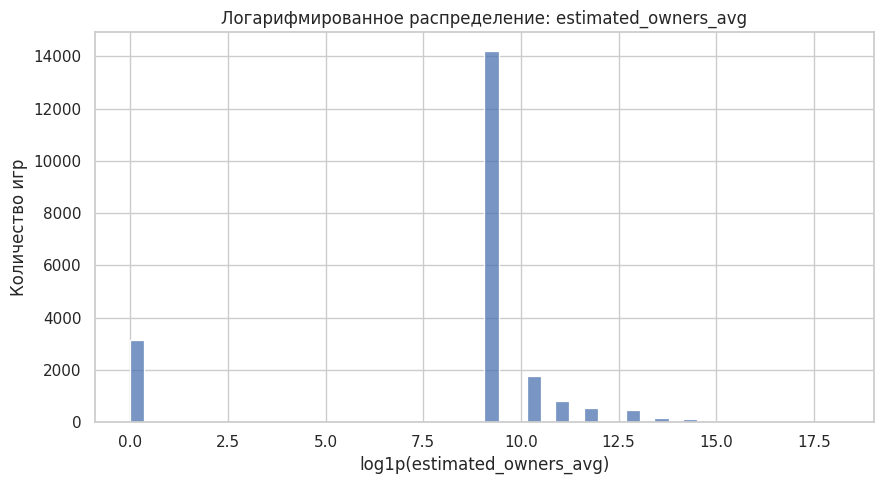

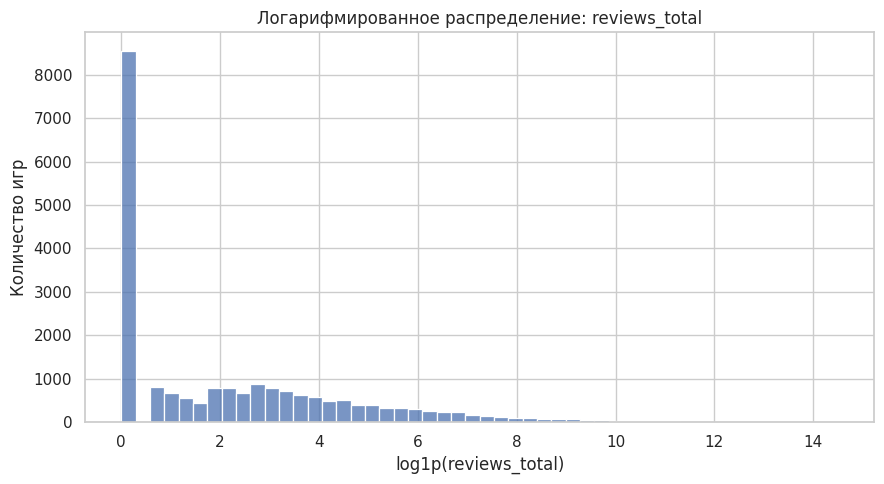

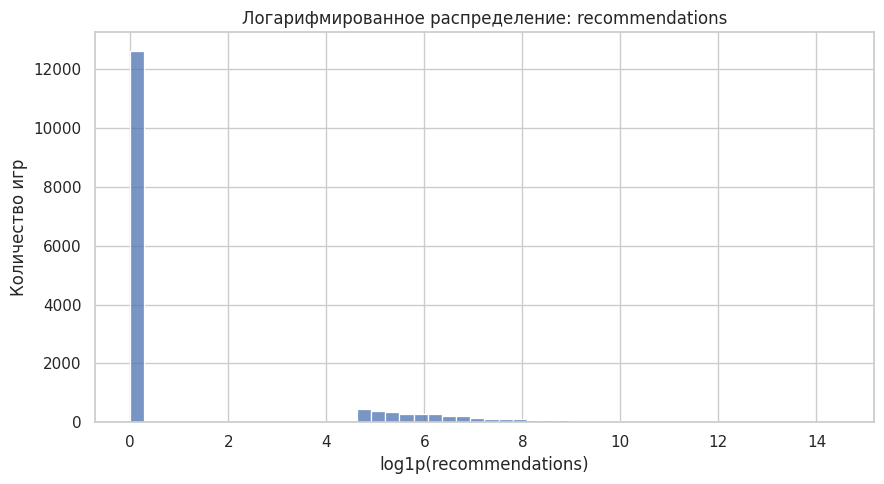

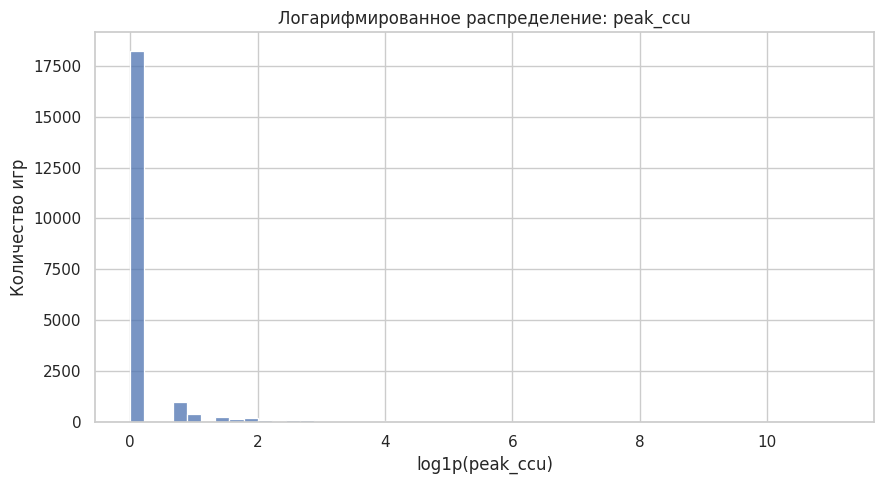

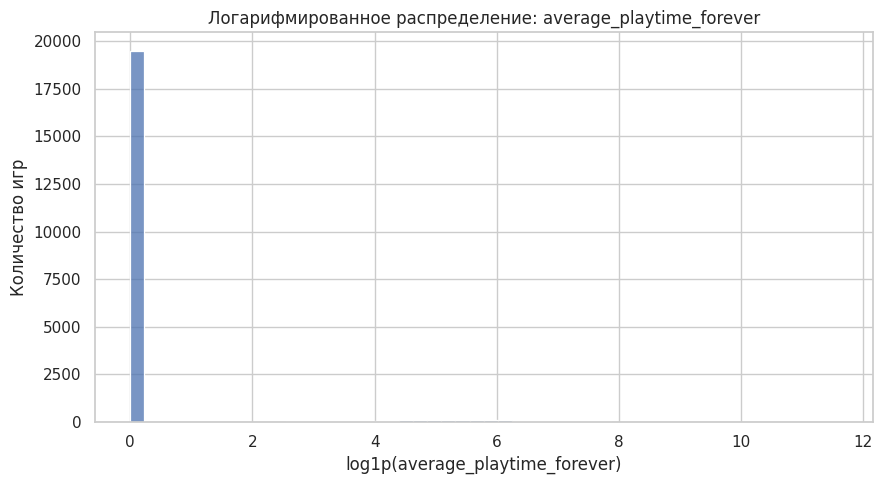

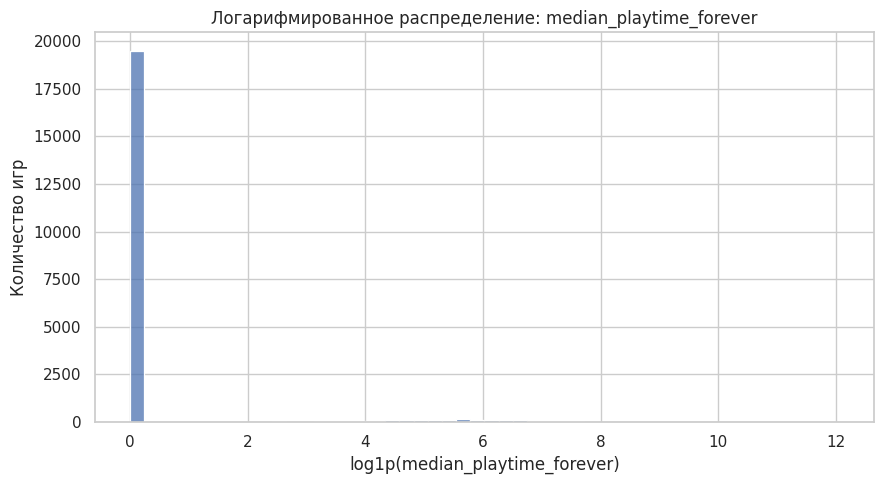

In [21]:
log_distribution_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
    "average_playtime_forever",
    "median_playtime_forever",
]

log_pdf = (
    df_clean
    .select(*log_distribution_columns)
    .sample(False, 0.15, seed=42)
    .toPandas()
)

for column_name in log_distribution_columns:
    series = log_pdf[column_name].dropna()

    if series.empty:
        continue

    plt.figure(figsize=(9, 5))
    sns.histplot(
        series.map(lambda value: __import__("math").log1p(value)),
        bins=50,
    )
    plt.xlabel(f"log1p({column_name})")
    plt.ylabel("Количество игр")
    plt.title(f"Логарифмированное распределение: {column_name}")
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / f"03_log_distribution_{column_name}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

## 13. Анализ цены

Цена имеет особый смысл: значение `0` соответствует бесплатной игре. Поэтому отдельно рассматривается доля бесплатных игр и распределение цен среди платных.

In [22]:
price_stats = (
    df_clean
    .select(
        spark_sum(
            when(col("price") == 0, 1).otherwise(0)
        ).alias("free_games"),
        spark_sum(
            when(col("price") > 0, 1).otherwise(0)
        ).alias("paid_games"),
        spark_sum(
            when(col("price").isNull(), 1).otherwise(0)
        ).alias("unknown_price"),
    )
    .first()
)

price_report = pd.DataFrame(
    {
        "category": [
            "Бесплатные",
            "Платные",
            "Цена неизвестна",
        ],
        "count": [
            price_stats["free_games"],
            price_stats["paid_games"],
            price_stats["unknown_price"],
        ],
    }
)

price_report["percent"] = (
    price_report["count"] / total_rows * 100
)

display(price_report)

,category,count,percent
0,Бесплатные,27904,19.769320
1,Платные,112008,79.355003
2,Цена неизвестна,1236,0.875677


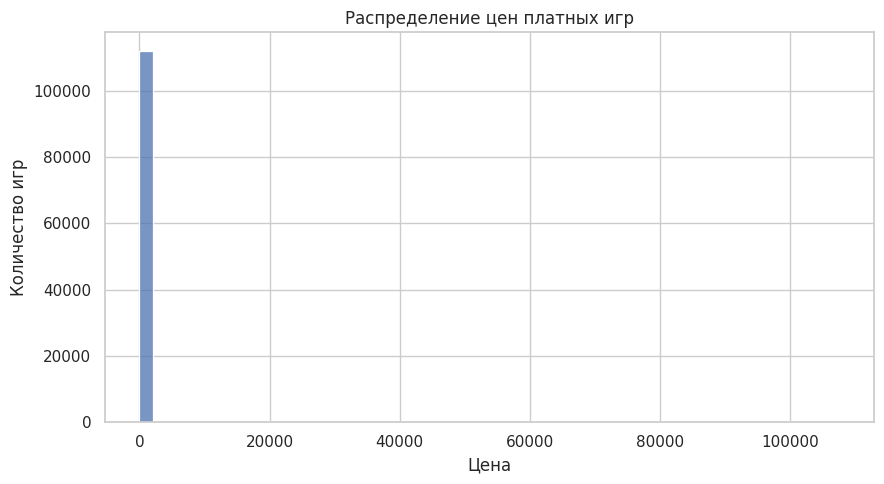

In [23]:
paid_price_pdf = (
    df_clean
    .filter(col("price") > 0)
    .select("price")
    .toPandas()
)

plt.figure(figsize=(9, 5))
sns.histplot(
    paid_price_pdf["price"],
    bins=50,
)
plt.xlabel("Цена")
plt.ylabel("Количество игр")
plt.title("Распределение цен платных игр")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "04_paid_price_distribution.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 14. Поиск выбросов методом IQR

Для числовых признаков рассчитываются первый и третий квартили, межквартильный размах и границы `Q1 - 1.5 × IQR` и `Q3 + 1.5 × IQR`.

Выход за границы IQR рассматривается как статистический выброс, но **не означает ошибку данных**. Для Steam естественны игры с очень большой аудиторией, количеством отзывов или временем игры, поэтому такие реальные экстремальные значения сохраняются.

In [24]:
outlier_columns = [
    "price",
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
]

outlier_rows = []

for column_name in outlier_columns:
    q1, median, q3 = (
        df_clean
        .select(
            percentile_approx(col(column_name), 0.25, 10000).alias("q1"),
            percentile_approx(col(column_name), 0.50, 10000).alias("median"),
            percentile_approx(col(column_name), 0.75, 10000).alias("q3"),
        )
        .first()
    )

    iqr = q3 - q1
    lower_bound = max(0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        df_clean
        .filter(
            (col(column_name) < lower_bound)
            | (col(column_name) > upper_bound)
        )
        .count()
    )

    non_null_count = (
        df_clean
        .filter(col(column_name).isNotNull())
        .count()
    )

    outlier_rows.append(
        {
            "column": column_name,
            "q1": q1,
            "median": median,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_count,
            "outlier_percent": (
                outlier_count / non_null_count * 100
                if non_null_count
                else 0
            ),
        }
    )

outlier_report = pd.DataFrame(outlier_rows)

display(outlier_report)

,column,q1,median,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percent
0,price,0.99,4.99,9.99,9.0,0.0,23.49,6665,4.763709
1,estimated_owners_avg,10000.00,10000.00,10000.00,0.0,10000.0,10000.00,46793,33.151727
2,reviews_total,0.00,3.00,35.00,35.0,0.0,87.50,24255,17.184090
3,recommendations,0.00,0.00,0.00,0.0,0.0,0.00,22217,20.908740
4,peak_ccu,0.00,0.00,0.00,0.0,0.0,0.00,19716,13.968317
5,average_playtime_forever,0.00,0.00,0.00,0.0,0.0,0.00,11373,8.057500
6,median_playtime_forever,0.00,0.00,0.00,0.0,0.0,0.00,11373,8.057500
7,achievements,0.00,8.00,21.00,21.0,0.0,52.50,7686,6.260997
8,dlc_count,0.00,0.00,0.00,0.0,0.0,0.00,20368,14.430243
9,supported_languages_count,1.00,1.00,4.00,3.0,0.0,8.50,20357,15.334609


In [25]:
outlier_report.to_csv(
    RESULTS_DIR / "outliers_iqr.csv",
    index=False,
)

### Boxplot наиболее скошенных признаков

Для наглядности используются логарифмические значения. Это позволяет увидеть основную массу наблюдений, не скрывая существование экстремальных значений.

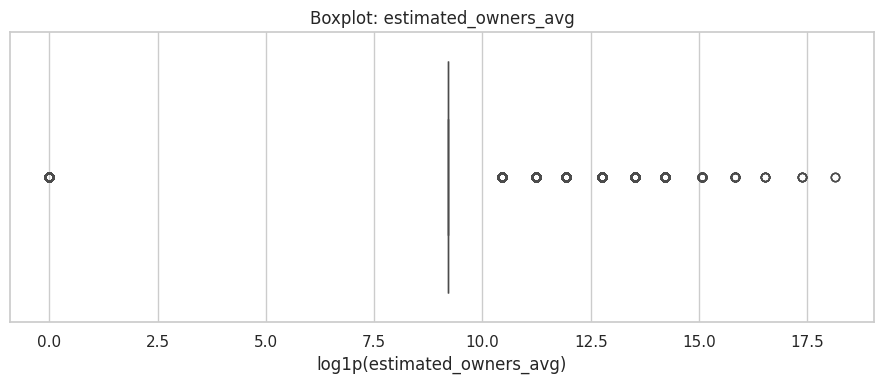

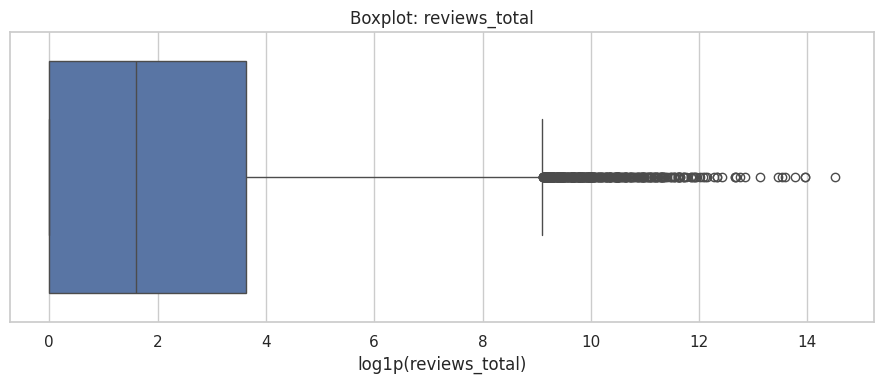

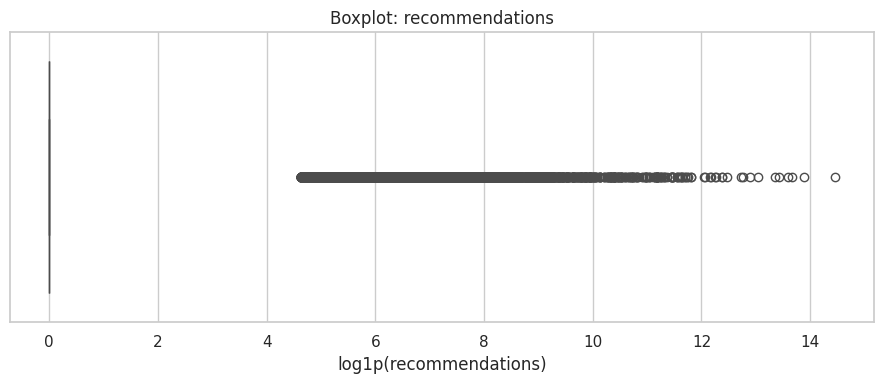

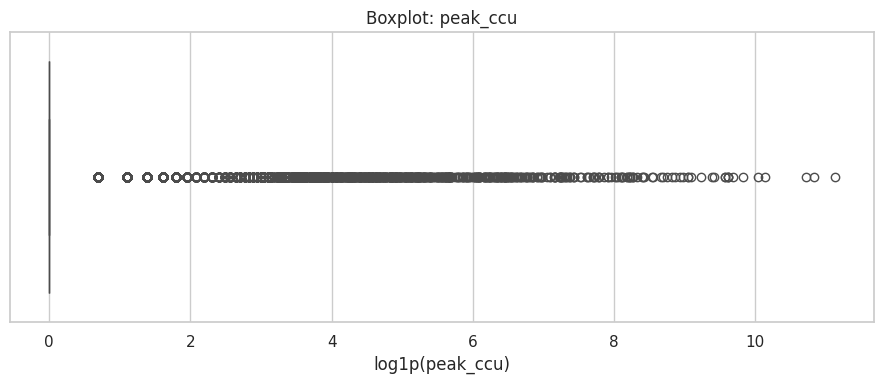

In [26]:
boxplot_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
]

boxplot_pdf = (
    df_clean
    .select(*boxplot_columns)
    .sample(False, 0.2, seed=42)
    .toPandas()
)

for column_name in boxplot_columns:
    series = boxplot_pdf[column_name].dropna()

    if series.empty:
        continue

    plt.figure(figsize=(9, 4))
    sns.boxplot(
        x=series.map(lambda value: __import__("math").log1p(value))
    )
    plt.xlabel(f"log1p({column_name})")
    plt.title(f"Boxplot: {column_name}")
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / f"05_boxplot_{column_name}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

## 15. Анализ годов выпуска

Исследуем распределение игр по году выпуска и динамику количества представленных в наборе игр.

In [27]:
release_year_df = (
    df_clean
    .filter(col("release_year").isNotNull())
    .groupBy("release_year")
    .count()
    .orderBy("release_year")
)

release_year_pdf = release_year_df.toPandas()

display(release_year_pdf.tail(20))

,release_year,count
10,2007,90
11,2008,158
12,2009,321
13,2010,255
14,2011,258
15,2012,322
16,2013,467
17,2014,1521
18,2015,2513
19,2016,4137


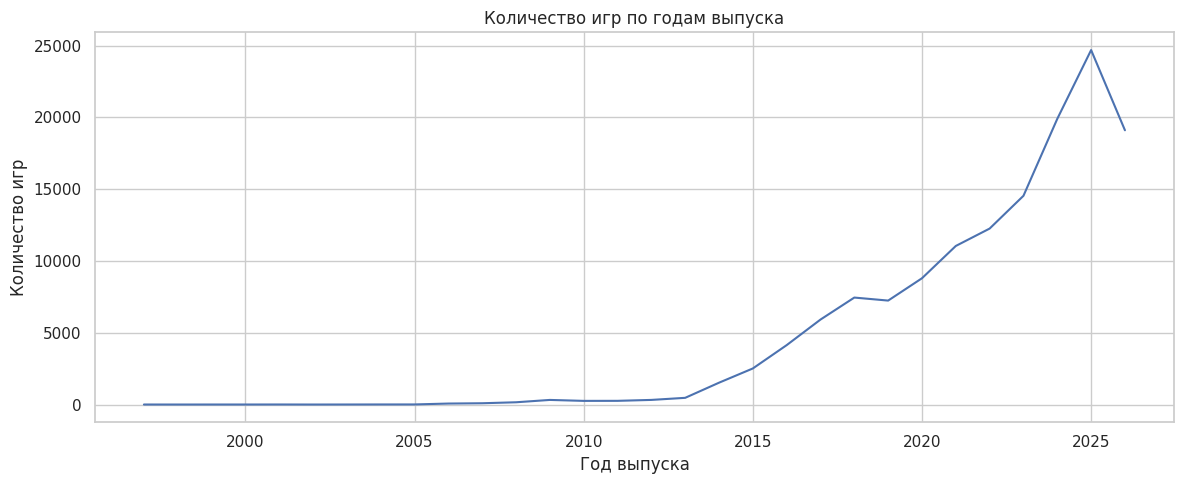

In [28]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=release_year_pdf,
    x="release_year",
    y="count",
)
plt.xlabel("Год выпуска")
plt.ylabel("Количество игр")
plt.title("Количество игр по годам выпуска")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "06_games_by_release_year.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

## 16. Анализ жанров, категорий и тегов

Многозначные признаки преобразуются в строки с помощью `explode`. Для каждого значения определяется количество игр, в которых оно встречается. Одинаковые значения у разных игр считаются независимыми наблюдениями.

In [29]:
genres_df = (
    df_clean
    .select(explode("genres").alias("genre"))
    .filter(col("genre").isNotNull())
    .groupBy("genre")
    .count()
    .orderBy(desc("count"))
)

categories_df = (
    df_clean
    .select(explode("categories").alias("category"))
    .filter(col("category").isNotNull())
    .groupBy("category")
    .count()
    .orderBy(desc("count"))
)

tags_df = (
    df_clean
    .select(explode("tags").alias("tag"))
    .filter(col("tag").isNotNull())
    .groupBy("tag")
    .count()
    .orderBy(desc("count"))
)

print("ТОП-20 жанров")
genres_df.show(20, truncate=False)

print("ТОП-20 категорий")
categories_df.show(20, truncate=False)

print("ТОП-20 тегов")
tags_df.show(20, truncate=False)

ТОП-20 жанров


+---------------------+-----+
|genre                |count|
+---------------------+-----+
|Indie                |93985|
|Casual               |59215|
|Action               |52564|
|Adventure            |51184|
|Simulation           |28901|
|Strategy             |26773|
|RPG                  |24288|
|Free To Play         |14494|
|Early Access         |13205|
|Sports               |5516 |
|Racing               |4561 |
|Massively Multiplayer|2882 |
|Utilities            |1094 |
|Design & Illustration|583  |
|Animation & Modeling |480  |
|Education            |466  |
|Violent              |406  |
|Video Production     |340  |
|Game Development     |322  |
|Gore                 |255  |
+---------------------+-----+
only showing top 20 rows

ТОП-20 категорий


+----------------------------+------+
|category                    |count |
+----------------------------+------+
|Single-player               |125680|
|Family Sharing              |115741|
|Steam Achievements          |65925 |
|Steam Cloud                 |37138 |
|Full controller support     |29631 |
|Multi-player                |23611 |
|Partial Controller Support  |15038 |
|Playable without Timed Input|14727 |
|PvP                         |14559 |
|Custom Volume Controls      |14161 |
|Co-op                       |13016 |
|Steam Trading Cards         |11596 |
|Steam Leaderboards          |10613 |
|Online PvP                  |10421 |
|Remote Play Together        |8535  |
|Shared/Split Screen         |8359  |
|Online Co-op                |8339  |
|Save Anytime                |8059  |
|Stereo Sound                |7945  |
|Mouse Only Option           |6937  |
+----------------------------+------+
only showing top 20 rows

ТОП-20 тегов


+--------------+-----+
|tag           |count|
+--------------+-----+
|Singleplayer  |50389|
|Indie         |48603|
|Action        |36858|
|Casual        |36618|
|Adventure     |35241|
|2D            |26813|
|3D            |18002|
|Simulation    |17914|
|Strategy      |17871|
|Puzzle        |16392|
|Atmospheric   |16296|
|RPG           |15767|
|Colorful      |14267|
|Pixel Graphics|13877|
|Story Rich    |13363|
|Exploration   |13247|
|Cute          |12684|
|First-Person  |12303|
|Fantasy       |11513|
|Arcade        |11505|
+--------------+-----+
only showing top 20 rows



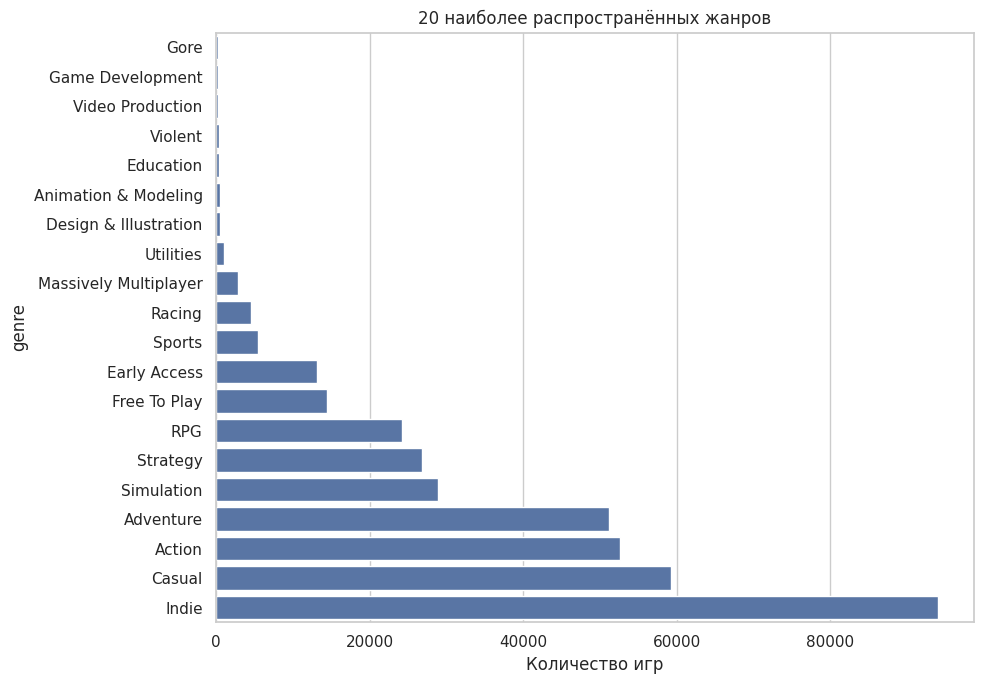

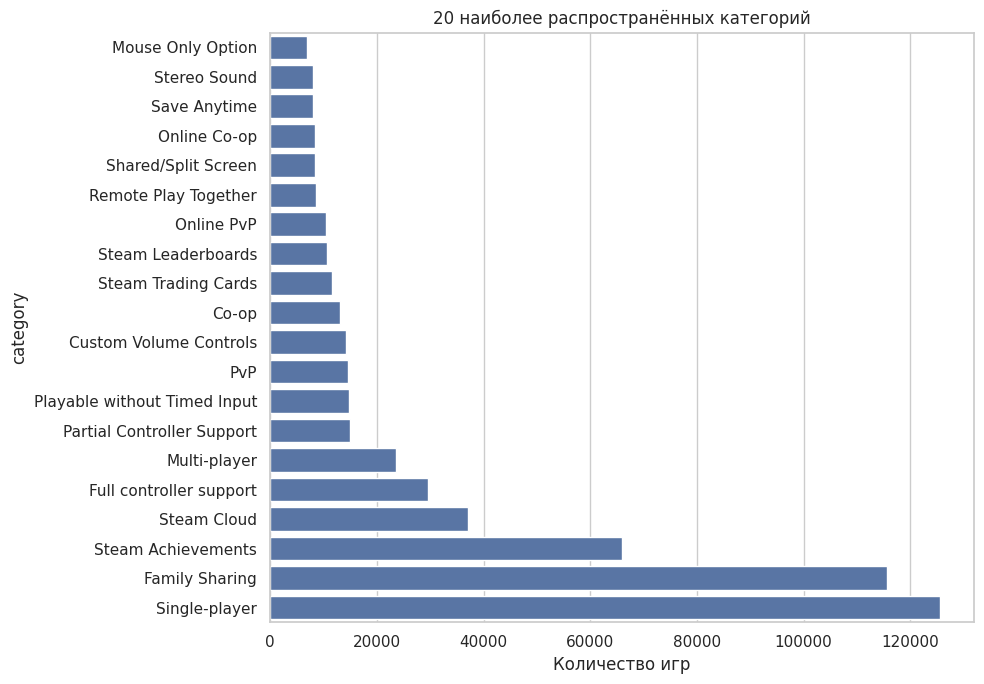

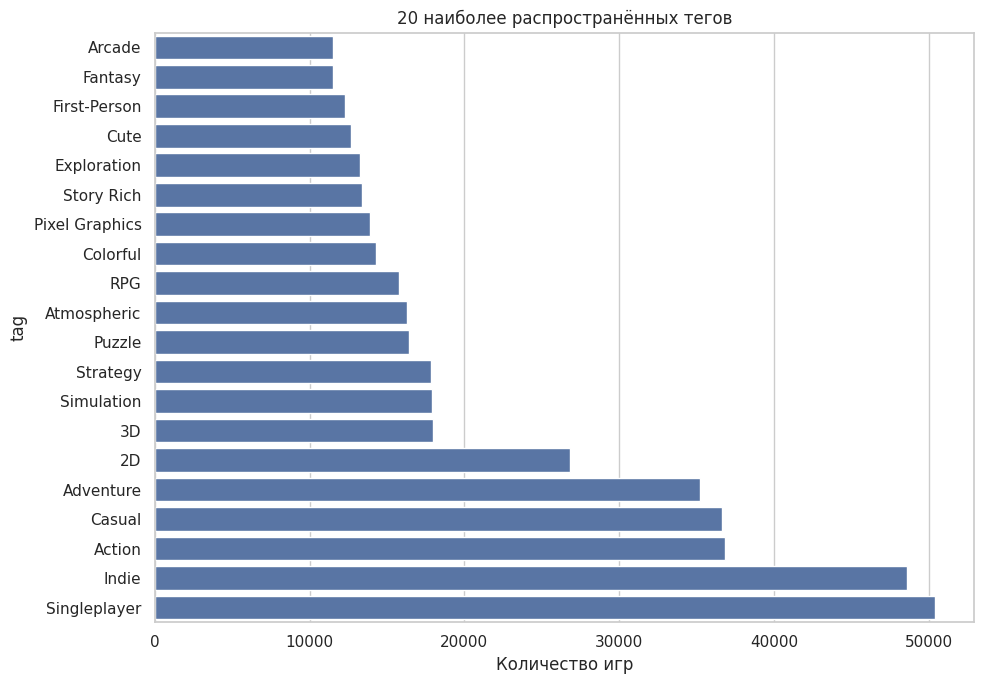

In [30]:
def show_top_multilabel(dataframe, column_name, title, filename):
    pdf = (
        dataframe
        .limit(20)
        .toPandas()
        .sort_values("count")
    )

    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=pdf,
        x="count",
        y=column_name,
    )
    plt.xlabel("Количество игр")
    plt.ylabel(column_name)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


show_top_multilabel(
    genres_df,
    "genre",
    "20 наиболее распространённых жанров",
    "07_top_genres.png",
)

show_top_multilabel(
    categories_df,
    "category",
    "20 наиболее распространённых категорий",
    "08_top_categories.png",
)

show_top_multilabel(
    tags_df,
    "tag",
    "20 наиболее распространённых тегов",
    "09_top_tags.png",
)

## 17. Распределение количества жанров, категорий и тегов на игру

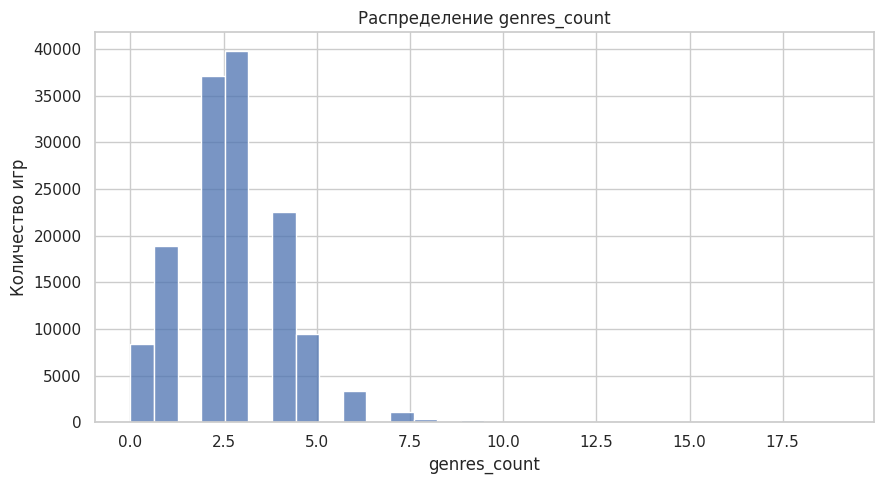

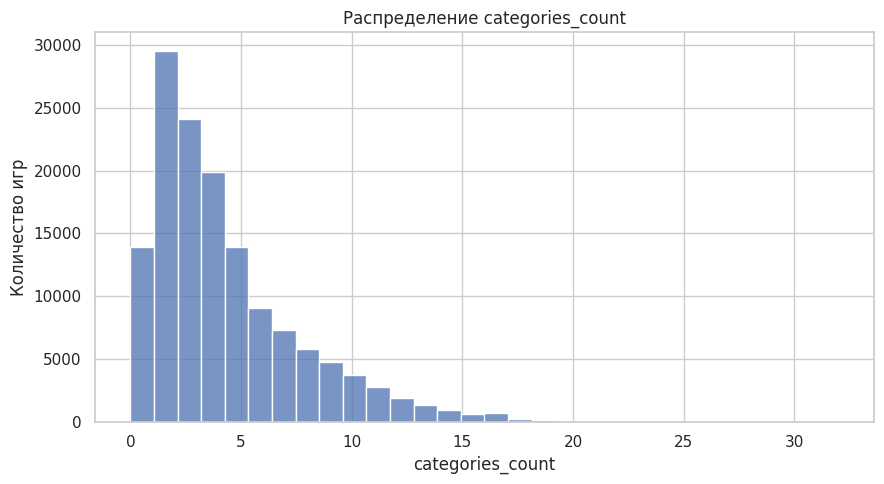

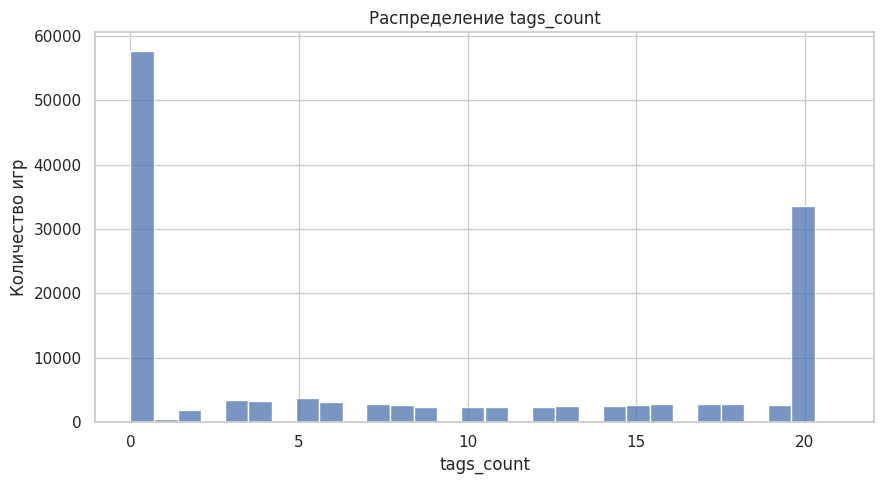

In [31]:
multilabel_pdf = (
    df_clean
    .select(
        "genres_count",
        "categories_count",
        "tags_count",
    )
    .toPandas()
)

for column_name in [
    "genres_count",
    "categories_count",
    "tags_count",
]:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        multilabel_pdf[column_name].dropna(),
        bins=30,
    )
    plt.xlabel(column_name)
    plt.ylabel("Количество игр")
    plt.title(f"Распределение {column_name}")
    plt.tight_layout()
    plt.savefig(
        PLOTS_DIR / f"10_{column_name}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

## 18. Показатели популярности

В качестве количественных показателей, связанных с популярностью игры, рассматриваются оценочное количество владельцев, число отзывов, рекомендации и пиковое количество одновременных пользователей.

`reviews_total` объединяет положительные и отрицательные отзывы, а `positive_ratio` показывает долю положительных отзывов среди всех отзывов.

In [32]:
popularity_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
]

popularity_summary = (
    df_clean
    .select(*popularity_columns)
    .summary(
        "count",
        "min",
        "25%",
        "50%",
        "mean",
        "75%",
        "max",
    )
)

popularity_summary.show(truncate=False)

+-------+--------------------+------------------+---------------+-----------------+
|summary|estimated_owners_avg|reviews_total     |recommendations|peak_ccu         |
+-------+--------------------+------------------+---------------+-----------------+
|count  |141148              |141148            |106257         |141148           |
|min    |0.0                 |0                 |0              |0                |
|25%    |10000.0             |0                 |0              |0                |
|50%    |10000.0             |3                 |0              |0                |
|mean   |75875.57032334854   |1055.1682843540113|1162.9214922311|47.48437809958342|
|75%    |10000.0             |35                |0              |0                |
|max    |1.5E8               |8815087           |5179195        |1013936          |
+-------+--------------------+------------------+---------------+-----------------+



## 19. Популярность в зависимости от жанра

Для жанров рассчитываются количество игр и медианные показатели популярности. Медиана используется вместо среднего из-за сильной асимметрии распределений.

In [33]:
genre_popularity_df = (
    df_clean
    .select(
        explode("genres").alias("genre"),
        "estimated_owners_avg",
        "reviews_total",
        "positive_ratio",
        "peak_ccu",
    )
    .filter(col("genre").isNotNull())
    .groupBy("genre")
    .agg(
        spark_sum(
            when(col("estimated_owners_avg").isNotNull(), 1).otherwise(0)
        ).alias("games_with_owners"),
        percentile_approx(
            col("estimated_owners_avg"),
            0.5,
            10000,
        ).alias("median_owners"),
        percentile_approx(
            col("reviews_total"),
            0.5,
            10000,
        ).alias("median_reviews"),
        percentile_approx(
            col("positive_ratio"),
            0.5,
            10000,
        ).alias("median_positive_ratio"),
        percentile_approx(
            col("peak_ccu"),
            0.5,
            10000,
        ).alias("median_peak_ccu"),
    )
    .filter(col("games_with_owners") >= 50)
    .orderBy(desc("median_owners"))
)

genre_popularity_df.show(20, truncate=False)

+---------------------+-----------------+-------------+--------------+---------------------+---------------+
|genre                |games_with_owners|median_owners|median_reviews|median_positive_ratio|median_peak_ccu|
+---------------------+-----------------+-------------+--------------+---------------------+---------------+
|Education            |466              |10000.0      |7             |0.7601351351351351   |0              |
|Massively Multiplayer|2882             |10000.0      |8             |0.6666666666666666   |0              |
|Sexual Content       |86               |10000.0      |32            |0.7058823529411765   |0              |
|Adventure            |51184            |10000.0      |7             |0.8132530120481928   |0              |
|Sports               |5516             |10000.0      |7             |0.7692307692307693   |0              |
|Audio Production     |227              |10000.0      |16            |0.75                 |0              |
|Video Production  

## 20. Корреляционный анализ

Для числовых признаков рассчитывается коэффициент корреляции Pearson. `app_id` в матрицу не включается.

Показатели с длинными правыми хвостами дополнительно анализируются в логарифмированном виде. Корреляция описывает статистическую связь между признаками и не означает причинно-следственную зависимость.

In [34]:
correlation_columns = [
    "price",
    "estimated_owners_avg",
    "positive",
    "negative",
    "reviews_total",
    "positive_ratio",
    "recommendations",
    "peak_ccu",
    "metacritic_score",
    "average_playtime_forever",
    "median_playtime_forever",
    "achievements",
    "dlc_count",
    "supported_languages_count",
    "full_audio_languages_count",
    "genres_count",
    "categories_count",
    "tags_count",
    "platform_count",
]

correlation_pdf = (
    df_clean
    .select(*correlation_columns)
    .toPandas()
)

correlation_matrix = correlation_pdf.corr(
    method="pearson",
    numeric_only=True,
)

display(correlation_matrix.round(3))

,price,estimated_owners_avg,positive,negative,reviews_total,positive_ratio,recommendations,peak_ccu,metacritic_score,average_playtime_forever,median_playtime_forever,achievements,dlc_count,supported_languages_count,full_audio_languages_count,genres_count,categories_count,tags_count,platform_count
price,1.000,0.001,0.001,0.001,0.001,-0.009,0.051,0.000,0.258,0.001,0.001,0.001,0.001,0.001,-0.000,-0.000,0.005,0.000,0.013
estimated_owners_avg,0.001,1.000,0.735,0.773,0.760,0.020,0.627,0.641,0.155,0.027,0.009,0.020,0.027,0.024,0.008,0.006,0.101,0.070,0.025
positive,0.001,0.735,1.000,0.818,0.996,0.022,0.907,0.847,0.182,0.014,0.005,0.014,0.020,0.022,0.005,-0.000,0.077,0.046,0.020
negative,0.001,0.773,0.818,1.000,0.869,0.001,0.743,0.831,0.101,0.016,0.005,0.010,0.020,0.017,0.006,0.002,0.061,0.038,0.008
reviews_total,0.001,0.760,0.996,0.869,1.000,0.019,0.903,0.866,0.175,0.014,0.005,0.013,0.020,0.022,0.006,-0.000,0.076,0.046,0.019
positive_ratio,-0.009,0.020,0.022,0.001,0.019,1.000,0.022,0.005,0.596,0.012,0.009,-0.004,0.004,0.010,-0.001,-0.068,0.100,0.183,0.088
recommendations,0.051,0.627,0.907,0.743,0.903,0.022,1.000,0.668,0.189,0.015,0.007,0.022,0.022,0.024,0.007,-0.002,0.111,0.048,0.023
peak_ccu,0.000,0.641,0.847,0.831,0.866,0.005,0.668,1.000,0.063,0.020,0.005,0.005,0.007,0.013,0.002,0.002,0.034,0.017,0.009
metacritic_score,0.258,0.155,0.182,0.101,0.175,0.596,0.189,0.063,1.000,0.162,0.150,0.085,0.110,0.184,0.081,-0.031,0.208,0.281,0.059
average_playtime_forever,0.001,0.027,0.014,0.016,0.014,0.012,0.015,0.020,0.162,1.000,0.937,0.005,0.017,0.005,0.001,0.006,0.014,0.028,-0.000


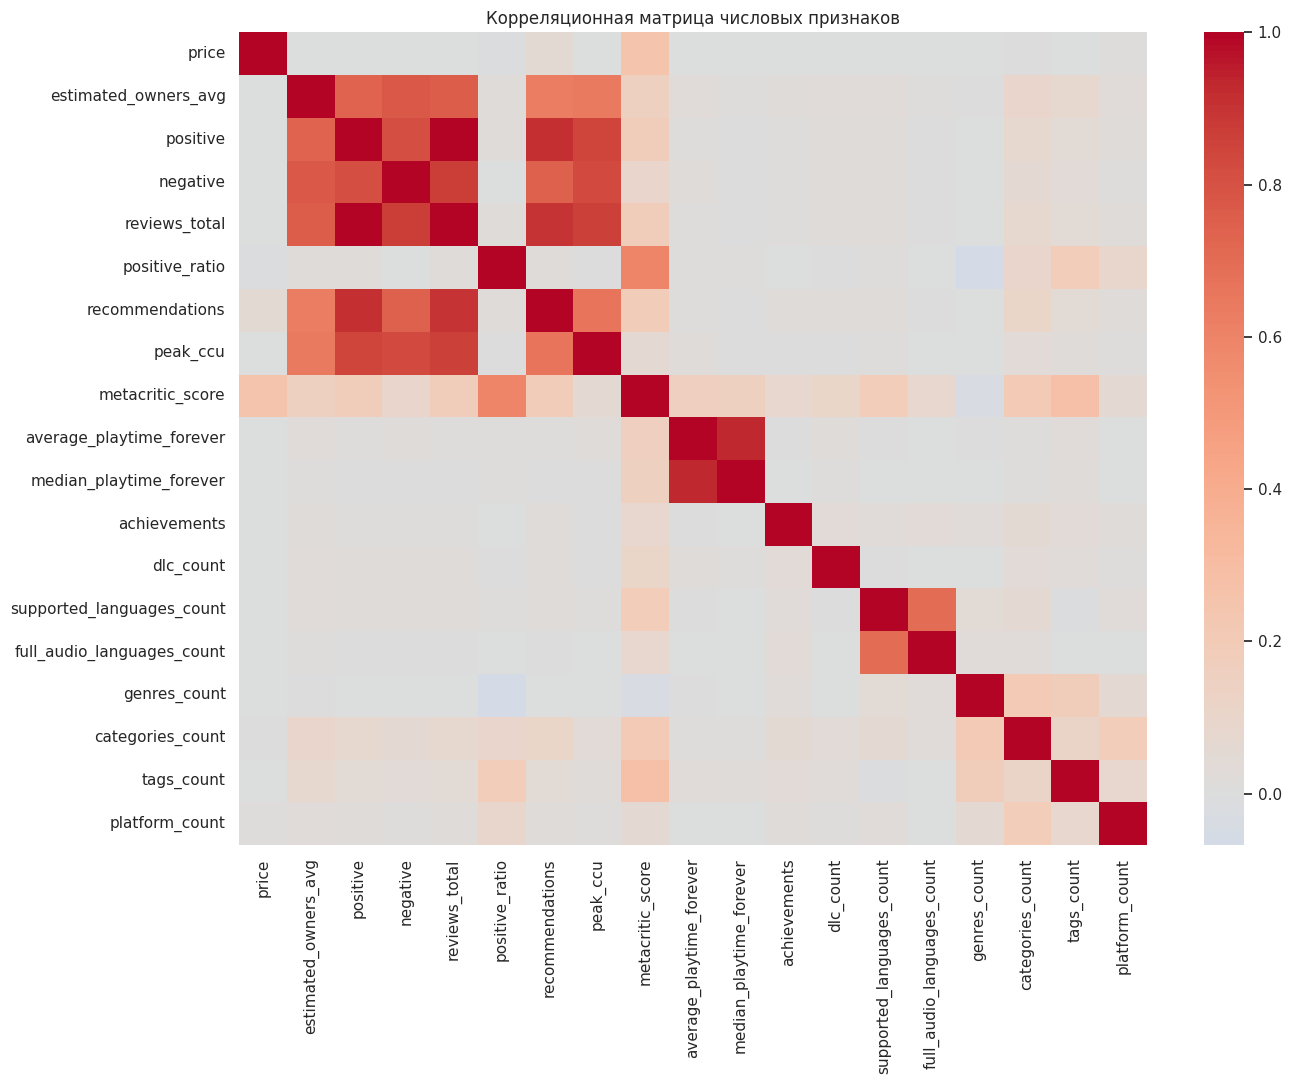

In [35]:
plt.figure(figsize=(14, 11))
sns.heatmap(
    correlation_matrix,
    annot=False,
    center=0,
    cmap="coolwarm",
)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "11_correlation_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Корреляции показателей популярности

Отдельно рассматриваем взаимосвязи основных показателей популярности, поскольку они могут описывать разные стороны востребованности игры.

In [36]:
popularity_correlation_columns = [
    "estimated_owners_avg",
    "reviews_total",
    "recommendations",
    "peak_ccu",
]

popularity_correlation = correlation_matrix.loc[
    popularity_correlation_columns,
    popularity_correlation_columns,
]

display(popularity_correlation.round(3))

,estimated_owners_avg,reviews_total,recommendations,peak_ccu
estimated_owners_avg,1.000,0.760,0.627,0.641
reviews_total,0.760,1.000,0.903,0.866
recommendations,0.627,0.903,1.000,0.668
peak_ccu,0.641,0.866,0.668,1.000


## 21. Итоговый набор данных для дальнейшего моделирования

После EDA сохраняем подготовленный DataFrame как переменную `df_model_ready`. На этом этапе данные не сохраняются обратно в исходную Iceberg-таблицу: дальнейшая подготовка признаков для регрессии и классификации будет выполнена в лабораторной работе №2.

In [37]:
df_model_ready = df_clean

print(
    "Финальное количество строк:",
    f"{df_model_ready.count():,}",
)

print(
    "Финальное количество столбцов:",
    len(df_model_ready.columns),
)

df_model_ready.printSchema()

Финальное количество строк: 141,148
Финальное количество столбцов: 32
root
 |-- app_id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- release_date: date (nullable = true)
 |-- price: double (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- categories: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- tags: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- positive: long (nullable = true)
 |-- negative: long (nullable = true)
 |-- recommendations: long (nullable = true)
 |-- peak_ccu: long (nullable = true)
 |-- metacritic_score: integer (nullable = true)
 |-- average_playtime_forever: long (nullable = true)
 |-- median_playtime_forever: long (nullable = true)
 |-- achievements: integer (nullable = true)
 |-- dlc_count: integer (nullable = true)
 |-- windows: boolean (nullable = true)
 |-- mac: boolean (nullable = true)
 |-- linux: boolean (nullable = true)
 

## 22. Выводы по разведочному анализу

В ходе работы были проверены структура и качество набора данных, исследованы пропущенные и нулевые значения, устранены дубликаты элементов внутри многозначных признаков, выполнена проверка логической корректности числовых значений.

Для числовых показателей рассчитаны описательные статистики и исследованы распределения. Для сильно асимметричных признаков использована логарифмическая визуализация. Выбросы определены методом IQR, при этом реальные экстремальные значения Steam-данных не удалялись автоматически.

Отдельно исследованы жанры, категории и теги, динамика количества игр по годам и взаимосвязи между числовыми характеристиками. Полученные результаты используются как основа для выбора признаков и постановки задач регрессии и бинарной классификации в следующей лабораторной работе.